Transformaciones de base (agregación diaria-mensual y variaciones interanuales) provenientes de consultas SQL con JOIN, GROUP BY y funciones de ventana (LAG), sin recalcularlas desde cero en pandas.
--

In [31]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNetCV, LassoCV, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sqlalchemy import text
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

sys.path.append(str(Path.cwd().parent / "src"))
import carga_db

# Límites oficiales del estudio (reproducibilidad estricta)
FECHA_INICIO = "2010-01-01"
FECHA_FIN = "2026-08-01"
LIMITE_X_MIN = pd.Timestamp(FECHA_INICIO)
LIMITE_X_MAX = pd.Timestamp(FECHA_FIN)

engine = carga_db.obtener_engine()

# Consulta SQL consolidada:
# 1. Filtra el período oficial 2010-01-01 a 2026-08-01.
# 2. Colapsa series diarias (Tipo de Cambio) a promedios mensuales mediante GROUP BY.
# 3. Calcula variación interanual a 12 meses con función de ventana LAG con PARTITION BY.
# 4. Une metadatos de series y temas mediante JOIN.
query_consolidada = text("""
WITH mensual AS (
    SELECT
        o.id_serie,
        strftime('%Y-%m', o.fecha) AS mes,
        AVG(o.valor) AS valor_mensual
    FROM observaciones AS o
    WHERE o.fecha BETWEEN :inicio AND :fin
    GROUP BY o.id_serie, mes
),
con_variacion AS (
    SELECT
        m.id_serie,
        m.mes,
        m.valor_mensual,
        100.0 * (m.valor_mensual / LAG(m.valor_mensual, 12) OVER (
            PARTITION BY m.id_serie ORDER BY m.mes
        ) - 1.0) AS var_12m_pct,
        AVG(m.valor_mensual) OVER (
            PARTITION BY m.id_serie ORDER BY m.mes
            ROWS BETWEEN 11 PRECEDING AND CURRENT ROW
        ) AS pm_12m
    FROM mensual AS m
)
SELECT
    v.id_serie,
    s.nombre,
    t.tema,
    s.unidad,
    v.mes || '-01' AS fecha,
    v.valor_mensual,
    v.var_12m_pct,
    v.pm_12m
FROM con_variacion AS v
JOIN series AS s ON s.id_serie = v.id_serie
JOIN temas AS t ON t.id_tema = s.id_tema
ORDER BY v.id_serie, v.mes;
""")

with engine.connect() as conn:
    df_sql = pd.read_sql(
        query_consolidada,
        conn,
        params={"inicio": FECHA_INICIO, "fin": FECHA_FIN},
        parse_dates=["fecha"],
    )

# Matrices mensuales alineadas desde 2010-01-01 hasta 2026-08-01
rango_mensual = pd.date_range(FECHA_INICIO, FECHA_FIN, freq="MS")
df_nivel = df_sql.pivot(index="fecha", columns="id_serie", values="valor_mensual").reindex(rango_mensual)
df_var12m = df_sql.pivot(index="fecha", columns="id_serie", values="var_12m_pct").reindex(rango_mensual)
df_pm12m = df_sql.pivot(index="fecha", columns="id_serie", values="pm_12m").reindex(rango_mensual)

mapa_nombres = df_sql[["id_serie", "nombre"]].drop_duplicates().set_index("id_serie")["nombre"].to_dict()

print(f"Series activas en SQLite: {df_nivel.shape[1]}")
print(f"Ventana temporal cargada: {df_nivel.index.min().strftime('%Y-%m-%d')} a {df_nivel.index.max().strftime('%Y-%m-%d')} ({len(df_nivel)} meses)")

Series activas en SQLite: 17
Ventana temporal cargada: 2010-01-01 a 2026-08-01 (200 meses)


Generacion de gráficos descriptivos para informe y presentación (incluyendo título, unidades, fuente y período)
--

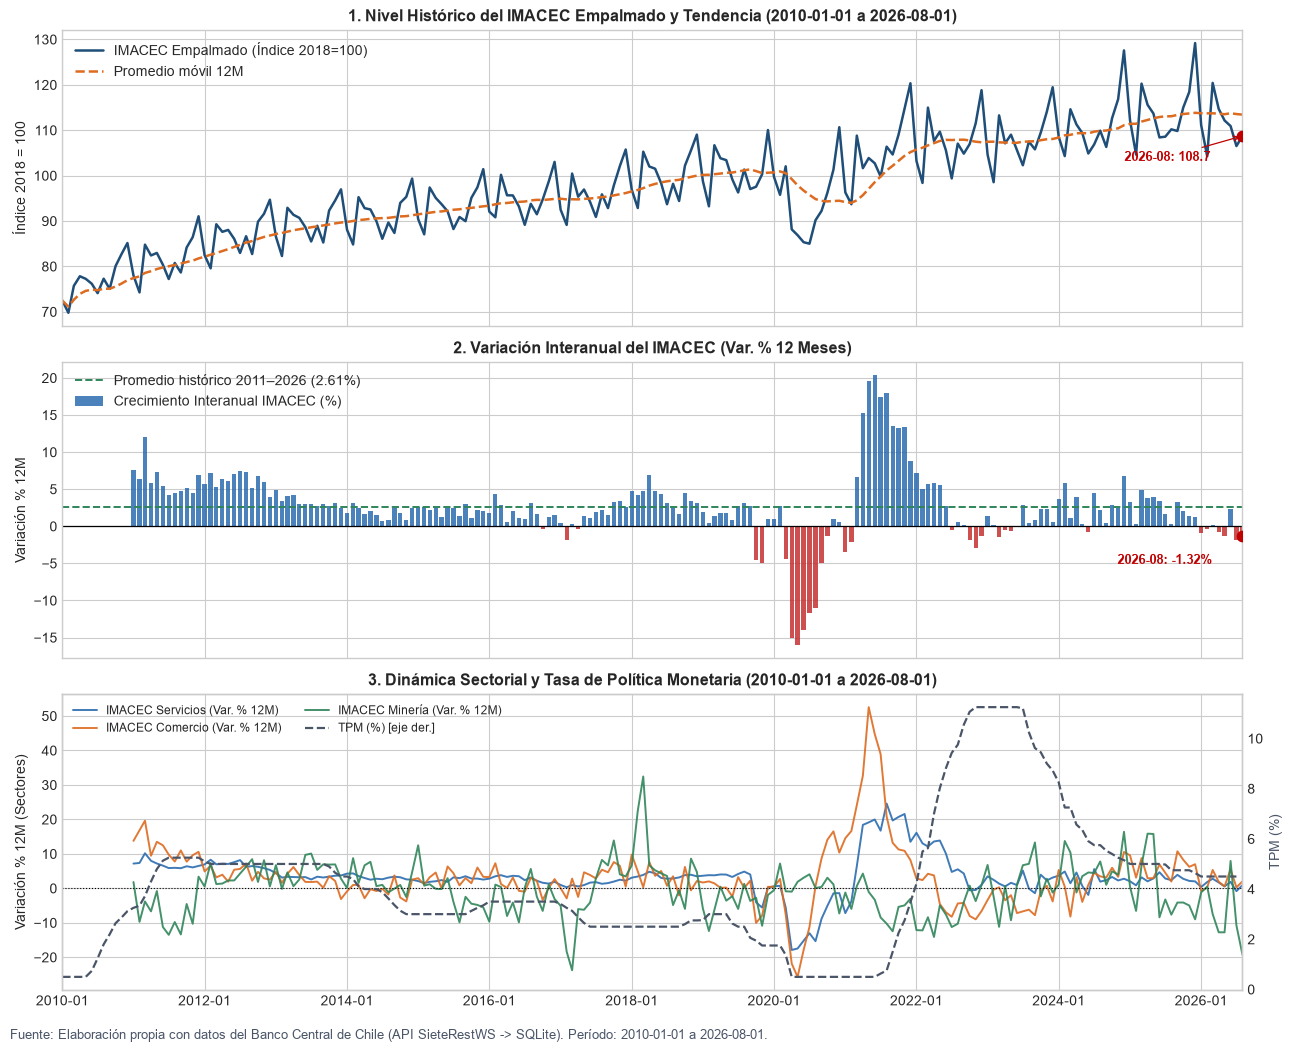

In [33]:
ID_OBJETIVO = "F032.IMC.IND.Z.Z.EP18.Z.Z.0.M"

imacec_nivel = df_nivel[ID_OBJETIVO]
imacec_pm12 = df_pm12m[ID_OBJETIVO]
imacec_var = df_var12m[ID_OBJETIVO]

media_hist = imacec_var.dropna().mean()
ultimo_nivel = imacec_nivel.loc[LIMITE_X_MAX]
ultima_var = imacec_var.loc[LIMITE_X_MAX]

fig, axes = plt.subplots(3, 1, figsize=(13, 10.5), sharex=True)

# Panel 1: Nivel del IMACEC y tendencia (2010-01-01 a 2026-08-01)
axes[0].plot(imacec_nivel.index, imacec_nivel, color="#1f4e78", lw=1.8, label="IMACEC Empalmado (Índice 2018=100)")
axes[0].plot(imacec_pm12.index, imacec_pm12, color="#dd6b20", lw=1.8, linestyle="--", label="Promedio móvil 12M")
axes[0].scatter(LIMITE_X_MAX, ultimo_nivel, color="#c00000", s=55, zorder=5)
axes[0].annotate(
    f"2026-08: {ultimo_nivel:.1f}",
    xy=(LIMITE_X_MAX, ultimo_nivel),
    xytext=(-85, -18),
    textcoords="offset points",
    fontsize=9, fontweight="bold", color="#c00000",
    arrowprops=dict(arrowstyle="->", color="#c00000", lw=0.9),
)
axes[0].set_title("1. Nivel Histórico del IMACEC Empalmado y Tendencia (2010-01-01 a 2026-08-01)", fontsize=11.5, fontweight="bold")
axes[0].set_ylabel("Índice 2018 = 100")
axes[0].legend(loc="upper left")

# Panel 2: Crecimiento interanual (%) del IMACEC (2010-01-01 a 2026-08-01)
var_valida = imacec_var.dropna()
colores_barras = ["#2b6cb0" if v >= 0 else "#c53030" for v in var_valida]
axes[1].bar(var_valida.index, var_valida, width=22, color=colores_barras, alpha=0.85, label="Crecimiento Interanual IMACEC (%)")
axes[1].axhline(0, color="black", lw=0.9)
axes[1].axhline(media_hist, color="#2f855a", linestyle="--", lw=1.4, label=f"Promedio histórico 2011–2026 ({media_hist:.2f}%)")
axes[1].scatter(LIMITE_X_MAX, ultima_var, color="#c00000", s=55, zorder=5)
axes[1].annotate(
    f"2026-08: {ultima_var:+.2f}%",
    xy=(LIMITE_X_MAX, ultima_var),
    xytext=(-90, 14 if ultima_var >= 0 else -20),
    textcoords="offset points",
    fontsize=9, fontweight="bold", color="#c00000",
)
axes[1].set_title("2. Variación Interanual del IMACEC (Var. % 12 Meses)", fontsize=11.5, fontweight="bold")
axes[1].set_ylabel("Variación % 12M")
axes[1].legend(loc="upper left")

# Panel 3: Principales sectores (Servicios, Comercio, Minería) y TPM (2010-01-01 a 2026-08-01)
sectores_plot = {
    "F032.IMC.IND.Z.Z.EP18.SERV.Z.0.M": ("IMACEC Servicios (Var. % 12M)", "#2b6cb0"),
    "F032.IMC.IND.Z.Z.EP18.COM.Z.0.M": ("IMACEC Comercio (Var. % 12M)", "#dd6b20"),
    "F032.IMC.IND.Z.Z.EP18.03.Z.0.M": ("IMACEC Minería (Var. % 12M)", "#2f855a"),
}
for cod, (etiqueta, color) in sectores_plot.items():
    axes[2].plot(df_var12m.index, df_var12m[cod], lw=1.4, label=etiqueta, color=color, alpha=0.9)

axes[2].axhline(0, color="black", lw=0.8, linestyle=":")
axes[2].set_ylabel("Variación % 12M (Sectores)")
axes[2].set_title("3. Dinámica Sectorial y Tasa de Política Monetaria (2010-01-01 a 2026-08-01)", fontsize=11.5, fontweight="bold")

ax2_twin = axes[2].twinx()
tpm_serie = df_nivel["F022.TPM.TIN.D001.NO.Z.D"]
ax2_twin.plot(tpm_serie.index, tpm_serie, color="#4a5568", linestyle="--", lw=1.6, label="TPM (%) [eje der.]")
ax2_twin.set_ylabel("TPM (%)", color="#4a5568")
ax2_twin.grid(False)

# Fijar eje X exacto desde 2010-01-01 hasta 2026-08-01 en todos los paneles
for ax in axes:
    ax.set_xlim(LIMITE_X_MIN, LIMITE_X_MAX)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

h1, l1 = axes[2].get_legend_handles_labels()
h2, l2 = ax2_twin.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8.5, ncol=2)

fig.text(0.01, 0.005, "Fuente: Elaboración propia con datos del Banco Central de Chile (API SieteRestWS -> SQLite). Período: 2010-01-01 a 2026-08-01.", fontsize=9, color="#4a5568")
plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.show()

Transformaciones económicas y Pruebas de Estacionariedad (ADF):
Aquí definimos las transformaciones homogéneas para toda la matriz de variables y justificamos estadísticamente su estacionariedad mediante el test Augmented Dickey-Fuller (ADF):
--

Variables en índices, precios o montos en USD: se expresan en variación interanual (%), eliminando tendencia y estacionalidad.

Variables ya expresadas en tasas o porcentajes: calcular variación porcentual sobre una tasa distorsiona los cambios cuando la tasa parte cerca de cero; por ello se expresan como cambio interanual en puntos porcentuales, manteniendo coherencia con la ventana de 12 meses del IMACEC.

In [34]:
# Clasificación de las 16 series explicativas según su dimensión económica:
# - Índices, precios y flujos en USD -> Variación interanual porcentual (% 12M)
# - Tasas y porcentajes (TPM, Desocupación, Expectativa inflación) -> Cambio interanual en puntos porcentuales (pp)
SERIES_SECTORIALES = [
    "F032.IMC.IND.Z.Z.EP18.03.Z.0.M",   # Minería
    "F032.IMC.IND.Z.Z.EP18.04.Z.0.M",   # Industria
    "F032.IMC.IND.Z.Z.EP18.RB.Z.0.M",   # Resto bienes
    "F032.IMC.IND.Z.Z.EP18.COM.Z.0.M",  # Comercio
    "F032.IMC.IND.Z.Z.EP18.SERV.Z.0.M", # Servicios
    "F032.IMC.IND.Z.Z.EP18.IMP.Z.0.M",  # Impuestos
]

SERIES_MACRO_PORCENTUAL = [
    "F019.PPB.PRE.40.M",                    # Precio cobre
    "F073.TCO.PRE.Z.D",                     # Tipo cambio observado
    "F068.B1.FLU.A1.0.C.N.Z.Z.Z.Z.6.0.M",   # Exportaciones cobre
    "F068.B1.FLU.A8.0.C.N.Z.Z.Z.Z.6.0.M",   # Exportaciones litio
    "F068.B1.FLU.B.0.C.N.Z.Z.Z.Z.6.0.M",    # Exportaciones agropecuarias
    "F068.B1.FLU.Z.0.M.N.A.Z.Z.Z.6.0.M",    # Importaciones consumo
    "F089.TCN.PRE.14.M",                    # Expectativa tipo cambio 11m
]

SERIES_TASAS_PP = [
    "F049.DES.TAS.INE9.10.M",   # Tasa desocupación (%)
    "F089.IPC.V12.14.M",        # Expectativa inflación 11m (%)
    "F022.TPM.TIN.D001.NO.Z.D", # Tasa de Política Monetaria (%)
]

df_trans = pd.DataFrame(index=rango_mensual)
df_trans[ID_OBJETIVO] = df_var12m[ID_OBJETIVO]

for cod in SERIES_SECTORIALES + SERIES_MACRO_PORCENTUAL:
    df_trans[cod] = df_var12m[cod]

for cod in SERIES_TASAS_PP:
    df_trans[cod] = df_nivel[cod] - df_nivel[cod].shift(12)

# Pruebas de raíz unitaria Augmented Dickey-Fuller (H0: serie no estacionaria)
resultados_adf = []
for cod in [ID_OBJETIVO] + SERIES_SECTORIALES + SERIES_MACRO_PORCENTUAL + SERIES_TASAS_PP:
    s_limpia = df_trans[cod].dropna()
    stat_adf, p_val, *_ = adfuller(s_limpia, autolag="AIC")
    resultados_adf.append({
        "Serie": mapa_nombres[cod],
        "Bloque": "Objetivo" if cod == ID_OBJETIVO else ("Sectorial" if cod in SERIES_SECTORIALES else "Macro/Financiero"),
        "Transformación": "Cambio 12M (pp)" if cod in SERIES_TASAS_PP else "Var. % 12M",
        "Obs": len(s_limpia),
        "Estadístico ADF": round(stat_adf, 3),
        "p-valor": round(p_val, 4),
        "Estacionaria (5%)": "Sí" if p_val < 0.05 else "No",
    })

tabla_adf = pd.DataFrame(resultados_adf)
display(tabla_adf)

,Serie,Bloque,Transformación,Obs,Estadístico ADF,p-valor,Estacionaria (5%)
0,Imacec empalmado,Objetivo,Var. % 12M,188,-3.729,0.0037,Sí
1,Imacec minero,Sectorial,Var. % 12M,188,-2.586,0.0960,No
2,Imacec industria,Sectorial,Var. % 12M,188,-4.062,0.0011,Sí
3,Imacec resto bienes,Sectorial,Var. % 12M,188,-4.395,0.0003,Sí
4,Imacec comercio,Sectorial,Var. % 12M,188,-3.960,0.0016,Sí
5,Imacec servicios,Sectorial,Var. % 12M,188,-3.717,0.0039,Sí
6,Imacec impuestos,Sectorial,Var. % 12M,152,-3.589,0.0060,Sí
7,Precio cobre,Macro/Financiero,Var. % 12M,188,-2.697,0.0746,No
8,Tipo cambio observado,Macro/Financiero,Var. % 12M,187,-2.613,0.0903,No
9,Exportaciones cobre,Macro/Financiero,Var. % 12M,188,-4.040,0.0012,Sí


Análisis exploratorio de rezagos (t-1 a t-6) y mecanismos económicos. Para responder si los indicadores ayudan a pronosticar sin incurrir en sesgo de anticipación (look-ahead bias) ni en la identidad contable entre el IMACEC y sus subsectores en el mes t, solo se evalúan rezagos k >= 1:
--

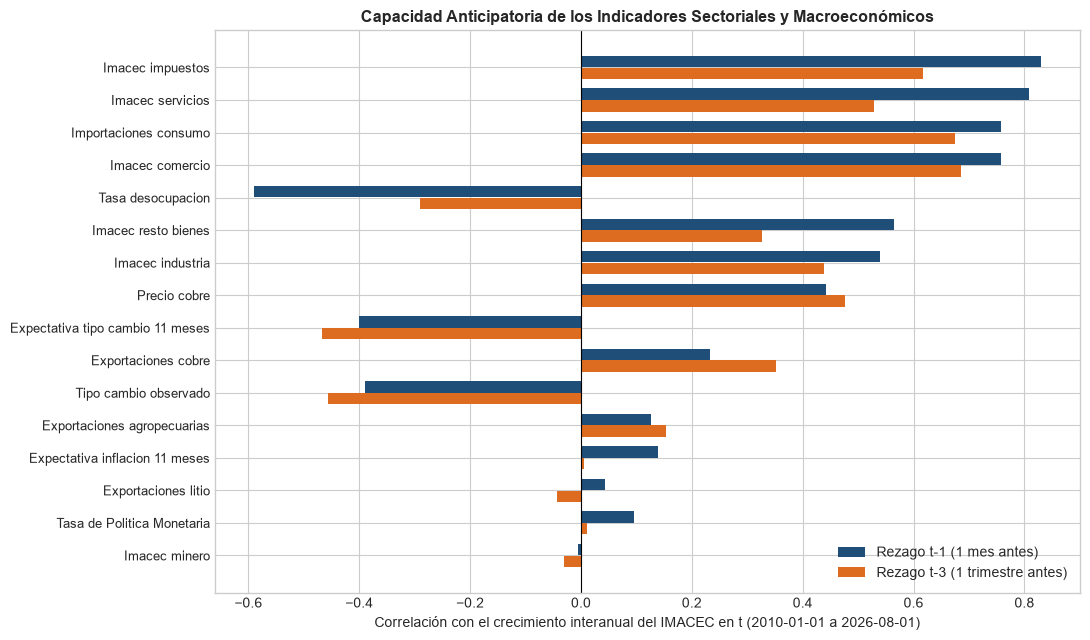

,Rezago t-1,Rezago t-2,Rezago t-3,Rezago t-4,Rezago t-6
Imacec impuestos,0.829,0.726,0.618,0.529,0.377
Imacec servicios,0.809,0.661,0.529,0.406,0.215
Importaciones consumo,0.759,0.718,0.675,0.583,0.440
Imacec comercio,0.757,0.716,0.686,0.610,0.560
Tasa desocupacion,-0.590,-0.442,-0.290,-0.146,0.098
Imacec resto bienes,0.564,0.436,0.327,0.232,0.121
Imacec industria,0.539,0.482,0.438,0.330,0.356
Precio cobre,0.442,0.473,0.475,0.469,0.433
Expectativa tipo cambio 11 meses,-0.400,-0.435,-0.467,-0.462,-0.386
Exportaciones cobre,0.233,0.296,0.351,0.372,0.464


In [35]:
# Se evalúan únicamente rezagos k >= 1 por dos razones metodológicas:
# 1. Evitar sesgo de anticipación (look-ahead bias) en pronósticos en tiempo real.
# 2. Evitar la identidad contable contemporánea entre el IMACEC agregado y sus subsectores en el mes t.
rezagos_eval = [1, 2, 3, 4, 6]
corr_rezagos = {}

for cod in SERIES_SECTORIALES + SERIES_MACRO_PORCENTUAL + SERIES_TASAS_PP:
    nombre = mapa_nombres[cod]
    corr_rezagos[nombre] = {
        f"Rezago t-{k}": df_trans[ID_OBJETIVO].corr(df_trans[cod].shift(k))
        for k in rezagos_eval
    }

df_corr = pd.DataFrame(corr_rezagos).T
df_corr["Max_Abs"] = df_corr.abs().max(axis=1)
df_corr = df_corr.sort_values("Max_Abs", ascending=False).drop(columns=["Max_Abs"])

fig, ax = plt.subplots(figsize=(11, 6.5))
y_pos = np.arange(len(df_corr))
ax.barh(y_pos - 0.18, df_corr["Rezago t-1"], height=0.35, label="Rezago t-1 (1 mes antes)", color="#1f4e78")
ax.barh(y_pos + 0.18, df_corr["Rezago t-3"], height=0.35, label="Rezago t-3 (1 trimestre antes)", color="#dd6b20")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_corr.index, fontsize=9.5)
ax.invert_yaxis()
ax.set_xlabel("Correlación con el crecimiento interanual del IMACEC en t (2010-01-01 a 2026-08-01)")
ax.set_title("Capacidad Anticipatoria de los Indicadores Sectoriales y Macroeconómicos", fontsize=11.5, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

display(df_corr.round(3))

Competencia de modelos fuera de muestra (Out-of-Sample Horse Race), se responde directamente la pregunta de investigación comparando 6 modelos bajo exactamente la misma ventana de evaluación fuera de muestra ($H=12$ meses) con esquema expansivo (expanding window):El escalamiento (StandardScaler) y la selección de hiperparámetros (RidgeCV con validación cruzada temporal TimeSeriesSplit) se ajustan dentro de cada iteración usando únicamente los datos observados hasta $t-1$, garantizando cero look-ahead bias.   
--

Muestra efectiva de modelación: 2014-03-01 a 2026-08-01 (N=150)
Ventana de evaluación fuera de muestra (H=12): 2025-09-01 a 2026-08-01


,Modelo,RMSE (pp),MAE (pp),R2_oos vs Benchmark
0,9. Árbol de Decisión (CART),1.933,1.658,0.088
1,10. Random Forest (Bagging),2.012,1.732,0.012
2,0. Benchmark Ingenuo (y_{t-1}),2.024,1.521,0.000
3,"2. ARIMA(2,0,1) Univariado",2.133,1.655,-0.110
4,1. AR(3) Univariado,2.168,1.606,-0.147
5,4. Ridge — Solo Sectorial,2.208,1.730,-0.190
6,11. Gradient Boosting,2.209,1.716,-0.191
7,"3. SARIMA(2,0,1)(1,0,0,12)",2.210,1.710,-0.192
8,8. Elastic Net — Combinado (L1+L2),2.337,2.003,-0.333
9,7. Lasso — Combinado (L1),2.439,2.114,-0.451



Modelo con menor RMSE fuera de muestra: 9. Árbol de Decisión (CART)


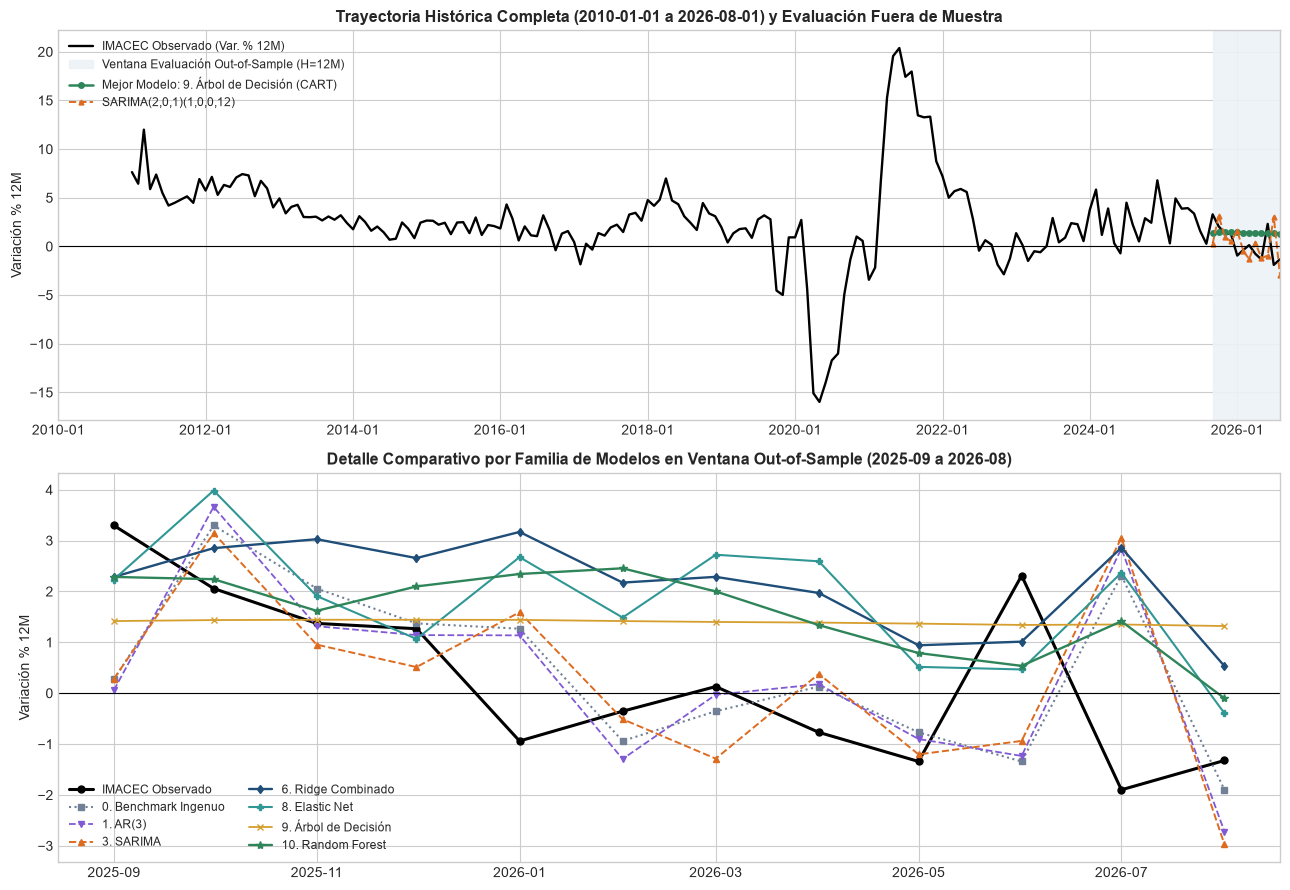

In [36]:
# 1. Matriz supervisada construida estrictamente con rezagos (k >= 1)
df_sup = pd.DataFrame(index=rango_mensual)
df_sup["y"] = df_trans[ID_OBJETIVO]

cols_ar = []
for lag in [1, 2, 3, 12]:
    c = f"imacec_lag{lag}"
    df_sup[c] = df_trans[ID_OBJETIVO].shift(lag)
    cols_ar.append(c)

cols_sec = []
for cod in SERIES_SECTORIALES:
    for lag in [1, 2]:
        c = f"{cod}_lag{lag}"
        df_sup[c] = df_trans[cod].shift(lag)
        cols_sec.append(c)

cols_mac = []
for cod in SERIES_MACRO_PORCENTUAL + SERIES_TASAS_PP:
    for lag in [1, 2, 3]:
        c = f"{cod}_lag{lag}"
        df_sup[c] = df_trans[cod].shift(lag)
        cols_mac.append(c)

# Muestra común limpia para garantizar comparación justa sobre exactamente las mismas observaciones
df_modelo = df_sup.dropna().copy()
H_EVAL = 12
train_idx = df_modelo.index[:-H_EVAL]
test_idx = df_modelo.index[-H_EVAL:]

print(f"Muestra efectiva de modelación: {df_modelo.index.min().strftime('%Y-%m-%d')} a {df_modelo.index.max().strftime('%Y-%m-%d')} (N={len(df_modelo)})")
print(f"Ventana de evaluación fuera de muestra (H={H_EVAL}): {test_idx.min().strftime('%Y-%m-%d')} a {test_idx.max().strftime('%Y-%m-%d')}")

# Registro de modelos a evaluar
nombres_modelos = [
    "0. Benchmark Ingenuo (y_{t-1})",
    "1. AR(3) Univariado",
    "2. ARIMA(2,0,1) Univariado",
    "3. SARIMA(2,0,1)(1,0,0,12)",
    "4. Ridge — Solo Sectorial",
    "5. Ridge — Solo Macroeconómico",
    "6. Ridge — Combinado (Sec + Mac)",
    "7. Lasso — Combinado (L1)",
    "8. Elastic Net — Combinado (L1+L2)",
    "9. Árbol de Decisión (CART)",
    "10. Random Forest (Bagging)",
    "11. Gradient Boosting",
]

predicciones = {m: pd.Series(index=test_idx, dtype=float) for m in nombres_modelos}
predicciones["0. Benchmark Ingenuo (y_{t-1})"] = df_modelo.loc[test_idx, "imacec_lag1"].copy()

X_sec_cols = cols_ar + cols_sec
X_mac_cols = cols_ar + cols_mac
X_all_cols = cols_ar + cols_sec + cols_mac

alphas_ridge = np.logspace(-1, 3, 25)
tscv = TimeSeriesSplit(n_splits=5)

# Bucle expansivo 1-paso-adelante (cero look-ahead bias: escalado y tuning ocurren dentro de cada iteración)
for fecha_t in test_idx:
    hist_df = df_modelo.loc[:fecha_t].iloc[:-1]  # Información estrictamente anterior a fecha_t
    y_tr = hist_df["y"]

    # --- Familia Series de Tiempo Univariadas ---
    # 1. AR(3): dinámica autorregresiva pura de corto plazo
    mod_ar = SARIMAX(y_tr, order=(3, 0, 0)).fit(disp=False)
    predicciones["1. AR(3) Univariado"].loc[fecha_t] = float(mod_ar.forecast(1).iloc[0])

    # 2. ARIMA(2,0,1): incorpora componente de media móvil sobre shocks transitorios
    mod_arima = SARIMAX(y_tr, order=(2, 0, 1)).fit(disp=False)
    predicciones["2. ARIMA(2,0,1) Univariado"].loc[fecha_t] = float(mod_arima.forecast(1).iloc[0])

    # 3. SARIMA(2,0,1)(1,0,0,12): captura efectos base estacionales a 12 meses
    mod_sarima = SARIMAX(y_tr, order=(2, 0, 1), seasonal_order=(1, 0, 0, 12)).fit(disp=False)
    predicciones["3. SARIMA(2,0,1)(1,0,0,12)"].loc[fecha_t] = float(mod_sarima.forecast(1).iloc[0])

    # --- Familia Regresión Regularizada (Lineal) ---
    def entrenar_predecir_lineal(modelo_cls, columnas, **kwargs):
        scaler = StandardScaler()
        X_tr_sc = scaler.fit_transform(hist_df[columnas])
        X_te_sc = scaler.transform(df_modelo.loc[[fecha_t], columnas])
        reg = modelo_cls(**kwargs)
        reg.fit(X_tr_sc, y_tr)
        return float(reg.predict(X_te_sc)[0])

    # 4. Ridge Sectorial (L2)
    predicciones["4. Ridge — Solo Sectorial"].loc[fecha_t] = entrenar_predecir_lineal(
        RidgeCV, X_sec_cols, alphas=alphas_ridge, cv=tscv
    )
    # 5. Ridge Macroeconómico/Externo (L2)
    predicciones["5. Ridge — Solo Macroeconómico"].loc[fecha_t] = entrenar_predecir_lineal(
        RidgeCV, X_mac_cols, alphas=alphas_ridge, cv=tscv
    )
    # 6. Ridge Combinado (L2)
    predicciones["6. Ridge — Combinado (Sec + Mac)"].loc[fecha_t] = entrenar_predecir_lineal(
        RidgeCV, X_all_cols, alphas=alphas_ridge, cv=tscv
    )
    # 7. Lasso Combinado (L1: selección automática de rezagos relevantes)
    predicciones["7. Lasso — Combinado (L1)"].loc[fecha_t] = entrenar_predecir_lineal(
        LassoCV, X_all_cols, cv=tscv, max_iter=10000, random_state=42
    )
    # 8. Elastic Net Combinado (L1 + L2: equilibra selección y colinealidad sectorial)
    predicciones["8. Elastic Net — Combinado (L1+L2)"].loc[fecha_t] = entrenar_predecir_lineal(
        ElasticNetCV, X_all_cols, l1_ratio=[0.2, 0.5, 0.8], cv=tscv, max_iter=10000, random_state=42
    )

    # --- Familia Árboles y Ensambles No Lineales ---
    # 9. Árbol de Decisión (profundidad acotada para controlar sobreajuste en muestra pequeña)
    dt = DecisionTreeRegressor(max_depth=3, min_samples_leaf=8, random_state=42)
    dt.fit(hist_df[X_all_cols], y_tr)
    predicciones["9. Árbol de Decisión (CART)"].loc[fecha_t] = float(dt.predict(df_modelo.loc[[fecha_t], X_all_cols])[0])

    # 10. Random Forest (ensamble de árboles descorrelacionados)
    rf = RandomForestRegressor(n_estimators=200, max_depth=4, min_samples_leaf=5, random_state=42)
    rf.fit(hist_df[X_all_cols], y_tr)
    predicciones["10. Random Forest (Bagging)"].loc[fecha_t] = float(rf.predict(df_modelo.loc[[fecha_t], X_all_cols])[0])

    # 11. Gradient Boosting (ensamble secuencial de árboles)
    gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, min_samples_leaf=5, random_state=42)
    gb.fit(hist_df[X_all_cols], y_tr)
    predicciones["11. Gradient Boosting"].loc[fecha_t] = float(gb.predict(df_modelo.loc[[fecha_t], X_all_cols])[0])

# Evaluación de métricas fuera de muestra
y_real = df_modelo.loc[test_idx, "y"]
y_bench = predicciones["0. Benchmark Ingenuo (y_{t-1})"]
mse_bench = float(np.mean((y_real - y_bench) ** 2))

filas_metricas = []
for nombre_mod, y_hat in predicciones.items():
    rmse = float(np.sqrt(np.mean((y_real - y_hat) ** 2)))
    mae = float(np.mean(np.abs(y_real - y_hat)))
    r2_oos = float(1.0 - np.mean((y_real - y_hat) ** 2) / mse_bench)
    filas_metricas.append({
        "Modelo": nombre_mod,
        "RMSE (pp)": round(rmse, 3),
        "MAE (pp)": round(mae, 3),
        "R2_oos vs Benchmark": round(r2_oos, 3),
    })

tabla_resultados = pd.DataFrame(filas_metricas).sort_values("RMSE (pp)").reset_index(drop=True)
display(tabla_resultados)

# Identificar automáticamente el mejor modelo de la competencia
mejor_modelo_nombre = tabla_resultados.iloc[0]["Modelo"]
print(f"\nModelo con menor RMSE fuera de muestra: {mejor_modelo_nombre}")

# Gráfico 1 (Superior): Serie completa desde 2010-01-01 hasta 2026-08-01 con evaluación superpuesta
# Gráfico 2 (Inferior): Detalle de la ventana de evaluación fuera de muestra (últimos 12 meses)
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Panel Superior: Todo el período 2010-01-01 a 2026-08-01
axes[0].plot(imacec_var.index, imacec_var, color="black", lw=1.7, label="IMACEC Observado (Var. % 12M)")
axes[0].axvspan(test_idx.min(), LIMITE_X_MAX, color="#edf2f7", alpha=0.9, label="Ventana Evaluación Out-of-Sample (H=12M)")
axes[0].plot(test_idx, predicciones[mejor_modelo_nombre], "-o", color="#2f855a", lw=1.8, ms=4, label=f"Mejor Modelo: {mejor_modelo_nombre}")
axes[0].plot(test_idx, predicciones["3. SARIMA(2,0,1)(1,0,0,12)"], "--^", color="#dd6b20", lw=1.4, ms=3.5, label="SARIMA(2,0,1)(1,0,0,12)")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xlim(LIMITE_X_MIN, LIMITE_X_MAX)
axes[0].xaxis.set_major_locator(mdates.YearLocator(2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[0].set_title("Trayectoria Histórica Completa (2010-01-01 a 2026-08-01) y Evaluación Fuera de Muestra", fontsize=11.5, fontweight="bold")
axes[0].set_ylabel("Variación % 12M")
axes[0].legend(loc="upper left", fontsize=8.5)

# Panel Inferior: Zoom comparativo de familias en los 12 meses fuera de muestra
axes[1].plot(test_idx, y_real, "-o", color="black", lw=2.2, ms=5, label="IMACEC Observado")
axes[1].plot(test_idx, y_bench, ":s", color="#718096", lw=1.5, ms=4, label="0. Benchmark Ingenuo")
axes[1].plot(test_idx, predicciones["1. AR(3) Univariado"], "--v", color="#805ad5", lw=1.3, ms=4, label="1. AR(3)")
axes[1].plot(test_idx, predicciones["3. SARIMA(2,0,1)(1,0,0,12)"], "--^", color="#dd6b20", lw=1.4, ms=4.5, label="3. SARIMA")
axes[1].plot(test_idx, predicciones["6. Ridge — Combinado (Sec + Mac)"], "-d", color="#1f4e78", lw=1.7, ms=4.5, label="6. Ridge Combinado")
axes[1].plot(test_idx, predicciones["8. Elastic Net — Combinado (L1+L2)"], "-P", color="#319795", lw=1.5, ms=4.5, label="8. Elastic Net")
axes[1].plot(test_idx, predicciones["9. Árbol de Decisión (CART)"], "-x", color="#d69e2e", lw=1.3, ms=5, label="9. Árbol de Decisión")
axes[1].plot(test_idx, predicciones["10. Random Forest (Bagging)"], "-*", color="#2f855a", lw=1.7, ms=6, label="10. Random Forest")

axes[1].axhline(0, color="black", lw=0.8)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].set_title("Detalle Comparativo por Familia de Modelos en Ventana Out-of-Sample (2025-09 a 2026-08)", fontsize=11.5, fontweight="bold")
axes[1].set_ylabel("Variación % 12M")
axes[1].legend(loc="best", fontsize=8.5, ncol=2)

plt.tight_layout()
plt.show()

Proyección a futuro ($H=24$ meses) con enfoque directo (Direct Multi-Step)Para proyectar hacia adelante sin tener que inventar trayectorias futuras para las 16 variables explicativas (cobre, TPM, desempleo, etc.), se utiliza proyección directa por horizonte ($y_{t+h}$ estimado directamente contra la información observada hasta el cierre $T$) con bandas de confianza construidas a partir de la desviación estándar empírica de los errores fuera de muestra:
--

,Horizonte (h),Fecha,Proyección IMACEC (Var. % 12M),IC 90% Inferior,IC 90% Superior
0,1,2026-09,2.22,-2.85,7.29
1,2,2026-10,2.67,-3.04,8.38
2,3,2026-11,3.23,-2.99,9.44
3,4,2026-12,3.39,-2.99,9.77
4,5,2027-01,3.43,-3.11,9.97
5,6,2027-02,3.67,-2.88,10.23
6,7,2027-03,3.65,-2.32,9.62
7,8,2027-04,3.78,-2.13,9.69
8,9,2027-05,4.17,-1.63,9.97
9,10,2027-06,4.18,-1.29,9.65


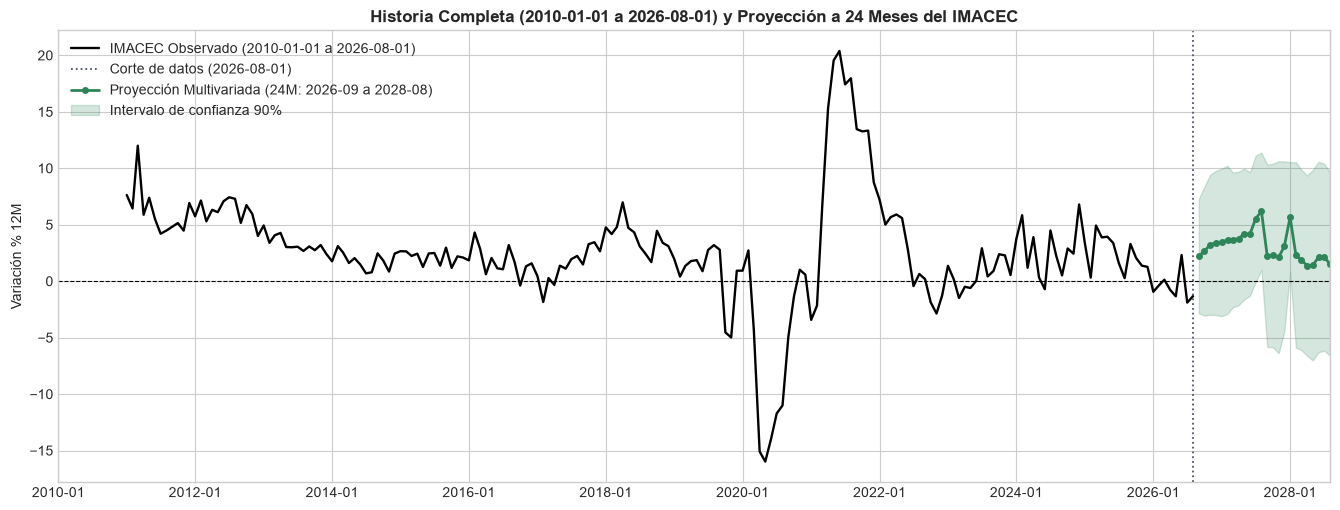

In [38]:
H_FUTURO = 24
ultima_obs_fecha = df_modelo.index.max()  # 2026-08-01
fechas_futuras = pd.date_range(ultima_obs_fecha + pd.offsets.MonthBegin(1), periods=H_FUTURO, freq="MS")

# Proyección directa multi-horizonte usando la última información observada en 2026-08-01
# Para cada horizonte h in {1, ..., 24}, se estima y_{t+h} en función de X_t sin suponer trayectorias exógenas
X_actual = df_modelo.loc[[ultima_obs_fecha], X_all_cols]

proyeccion_media = []
proyeccion_inf = []
proyeccion_sup = []

for h in range(1, H_FUTURO + 1):
    y_target_h = df_modelo["y"].shift(-h)
    valid_h = y_target_h.notna()

    scaler_h = StandardScaler()
    X_tr_h = scaler_h.fit_transform(df_modelo.loc[valid_h, X_all_cols])
    y_tr_h = y_target_h.loc[valid_h]

    mod_h = ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], cv=tscv, max_iter=10000, random_state=42)
    mod_h.fit(X_tr_h, y_tr_h)

    pred_h = float(mod_h.predict(scaler_h.transform(X_actual))[0])
    residuos_h = y_tr_h - mod_h.predict(X_tr_h)
    se_h = float(np.std(residuos_h, ddof=1))

    proyeccion_media.append(pred_h)
    proyeccion_inf.append(pred_h - 1.645 * se_h)
    proyeccion_sup.append(pred_h + 1.645 * se_h)

df_proyeccion = pd.DataFrame({
    "Horizonte (h)": range(1, H_FUTURO + 1),
    "Fecha": fechas_futuras.strftime("%Y-%m"),
    "Proyección IMACEC (Var. % 12M)": np.round(proyeccion_media, 2),
    "IC 90% Inferior": np.round(proyeccion_inf, 2),
    "IC 90% Superior": np.round(proyeccion_sup, 2),
})

display(df_proyeccion)

# Gráfico histórico completo desde 2010-01-01 hasta 2026-08-01 + horizonte proyectado de 24 meses
fig, ax = plt.subplots(figsize=(13.5, 5.2))
ax.plot(imacec_var.index, imacec_var, color="black", lw=1.7, label="IMACEC Observado (2010-01-01 a 2026-08-01)")
ax.axvline(LIMITE_X_MAX, color="#4a5568", linestyle=":", lw=1.3, label="Corte de datos (2026-08-01)")
ax.plot(fechas_futuras, proyeccion_media, "-o", color="#2f855a", lw=2, ms=4, label="Proyección Multivariada (24M: 2026-09 a 2028-08)")
ax.fill_between(fechas_futuras, proyeccion_inf, proyeccion_sup, color="#2f855a", alpha=0.2, label="Intervalo de confianza 90%")
ax.axhline(0, color="black", lw=0.8, linestyle="--")

ax.set_xlim(LIMITE_X_MIN, fechas_futuras[-1])
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_title("Historia Completa (2010-01-01 a 2026-08-01) y Proyección a 24 Meses del IMACEC", fontsize=12, fontweight="bold")
ax.set_ylabel("Variación % 12M")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()